In [1]:

%cd ..

from pathlib import Path
print(Path.cwd())

import numpy as np
import matplotlib.pyplot as plt

from hardware import ammeter, ammeter_uncertainty, gaussmeter, gaussmeter_uncertainty, horizontal_coils, vertical_coils, modulation_coils, horizontal_coils_uncertainty, vertical_coils_uncertainty, modulation_coils_uncertainty
from scope_header import DSOX1204G, self_test, load_waveforms


plt.rcParams.update({
    "font.sans-serif": ["Cabin", "Libertinus Sans", "DejaVu Sans"],
    "font.serif": ["Libertinus Serif"],
    "font.family": "sans-serif",
    "font.style": "normal",
    "font.weight": "normal",
    "font.size": 14,
    "axes.labelsize": 16,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.labelweight": "normal",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 14,
    "legend.title_fontsize": 14,
    "figure.titlesize": 18,
    "figure.titleweight": "bold",
    "mathtext.fontset": "cm",
    "mathtext.default": "it",
    "axes.unicode_minus": False,
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.titlecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "legend.edgecolor": "black",
})
%matplotlib inline

from scipy.optimize import curve_fit
from scipy import signal

# scope = DSOX1204G()


c:\Users\njwan\OneDrive - University of Toronto\Documents\Year 3\3F\PHY327\1 - Optical Pumping in Rubidium\code
c:\Users\njwan\OneDrive - University of Toronto\Documents\Year 3\3F\PHY327\1 - Optical Pumping in Rubidium\code


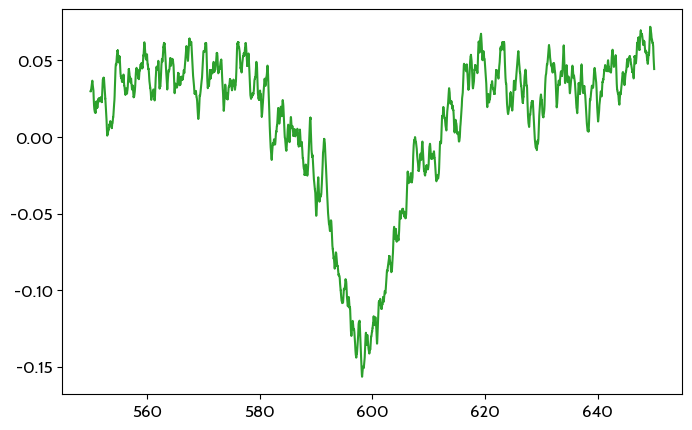

In [7]:
data = load_waveforms("data/31/frequency_sweep_test_552.npz")
t, V1, V2 = data[1][0], data[1][1], data[2][1]


N = 800
t = np.convolve(t, np.ones(N)/N, mode='valid')
V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
V2 = np.convolve(V2, np.ones(N)/N, mode='valid')

# fig0, ax0 = plt.subplots(figsize=(8, 6))
# ax0.plot(t, V1, label='Channel 1: Gaussmeter', color='goldenrod')
# ax0.plot(t, V2*5-2, label='Channel 2: Picoammeter', color='tab:green')
# ax0.set_xlabel('Time (s)')
# ax0.set_ylabel('Scope Signal (arb. units)')
# ax0.legend()

frequencies = np.linspace(550, 650, len(t))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(frequencies, V2, label='Channel 2: Picoammeter', color='tab:green')


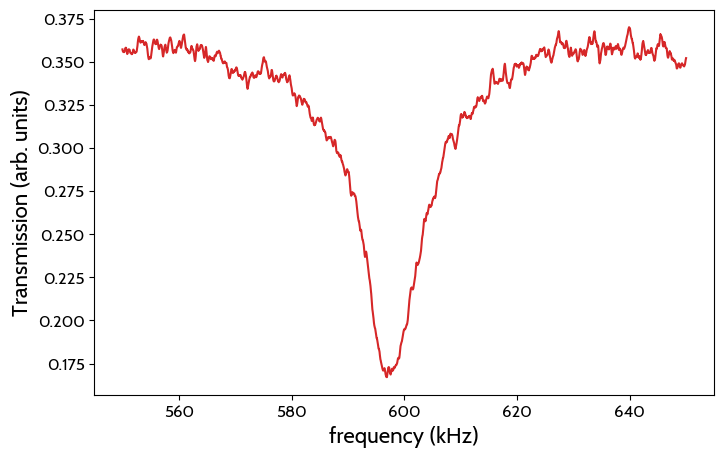

In [9]:
#test averaging multiple sweeps with 8 Vpp at 1.45 G

def plot_average(dnums, filename, freq_low = 550, freq_high = 650):
    transmissions = []
    for dnum in dnums:
        data = load_waveforms(f"data/31/{filename}_{dnum}.npz")
        t, V1, V2 = data[1][0], data[1][1], data[2][1]
        N = 100
        t = np.convolve(t, np.ones(N)/N, mode='valid')
        V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
        transmissions.append(V2)
    np.array(transmissions)
    frequencies = np.linspace(freq_low, freq_high, len(t))
    avg_transmission = np.mean(transmissions, axis=0)
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(frequencies, avg_transmission, label='Average Transmission', color='tab:red')
    ax.set_xlabel('frequency (kHz)')
    ax.set_ylabel('Transmission (arb. units)')

plot_average(range(553, 563), "first_sweep", freq_low=550, freq_high=650)

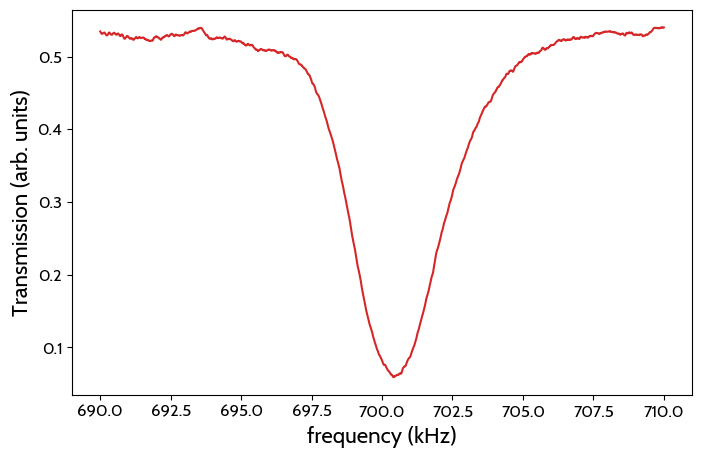

In [13]:
# 1Vpp, 1.67 G, sweep 690 to 710 kHz

plot_average(range(563, 585), "low_pow_sweep", freq_low=690, freq_high=710)

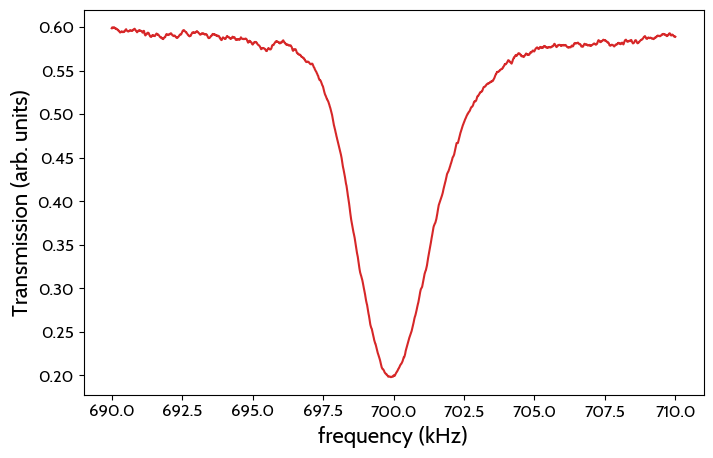

In [23]:
# 0.5 Vpp, 1.69 G, sweep 690 to 710 kHz
plot_average(range(585, 605), "0.5Vpp_sweep", freq_low=690, freq_high=710)

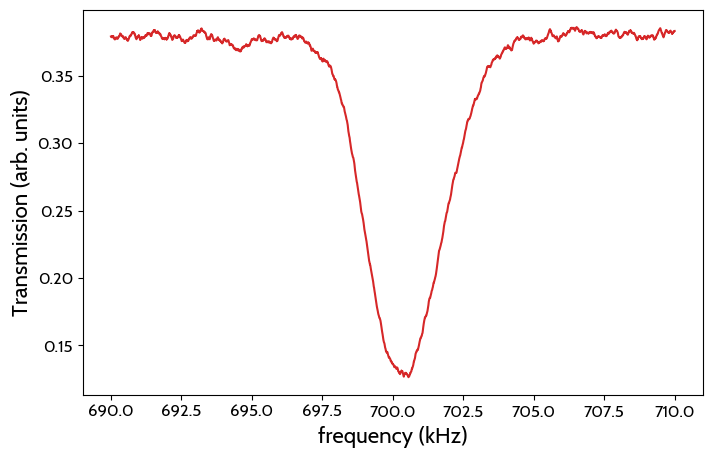

In [32]:
# 0.2 Vpp, 1.69 G, sweep 695 to 710 kHz
plot_average(range(605, 625), "0.2Vpp_sweep", freq_low=690, freq_high=710)

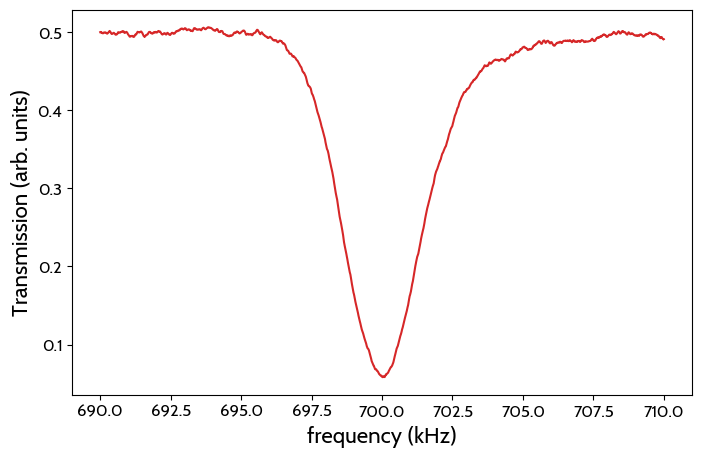

In [33]:
# 0.7 Vpp, 1.69 G, sweep 695 to 710 kHz
plot_average(range(625, 645), "0.7Vpp_sweep", freq_low=690, freq_high=710)

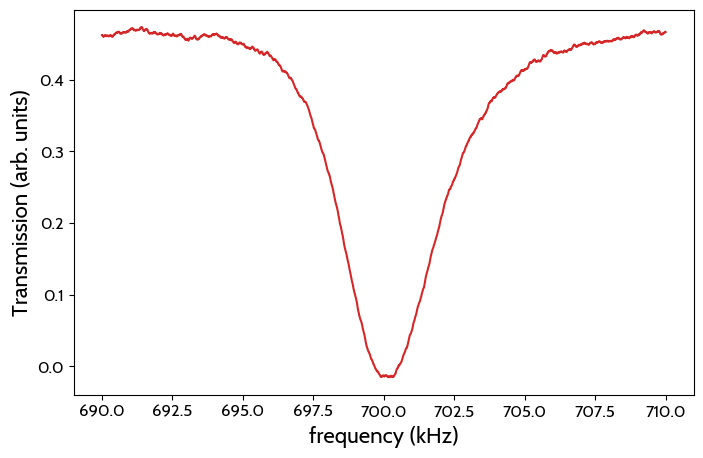

In [40]:
# 1.3 Vpp, 1.69 G, sweep 695 to 710 kHz
plot_average(range(645, 663), "1.3Vpp_sweep", freq_low=690, freq_high=710)

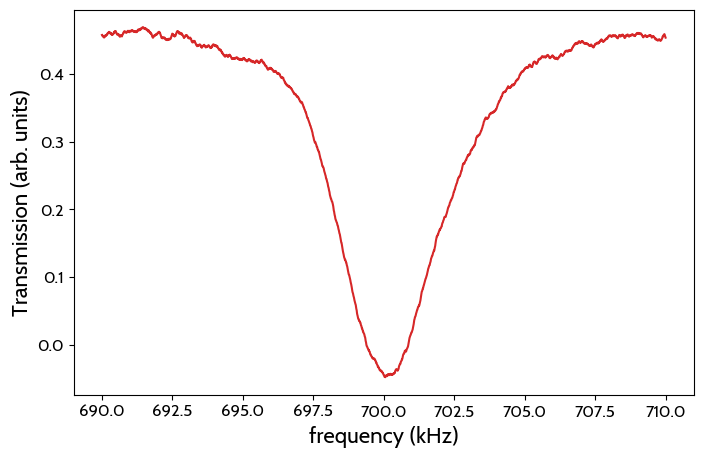

In [42]:
# 1.6 Vpp, 1.69 G, sweep 695 to 710 kHz
plot_average(range(663, 675), "1.6Vpp_sweep", freq_low=690, freq_high=710)

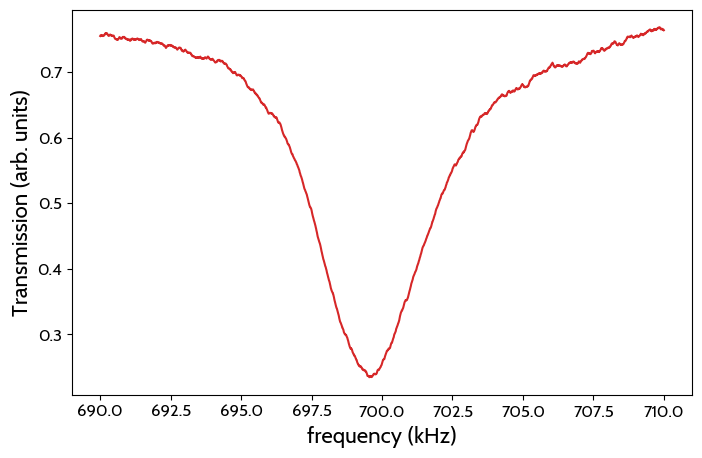

In [44]:
# 2.0 Vpp, 1.69 G, sweep 695 to 710 kHz
plot_average(range(678, 693), "2.0Vpp_sweep", freq_low=690, freq_high=710)

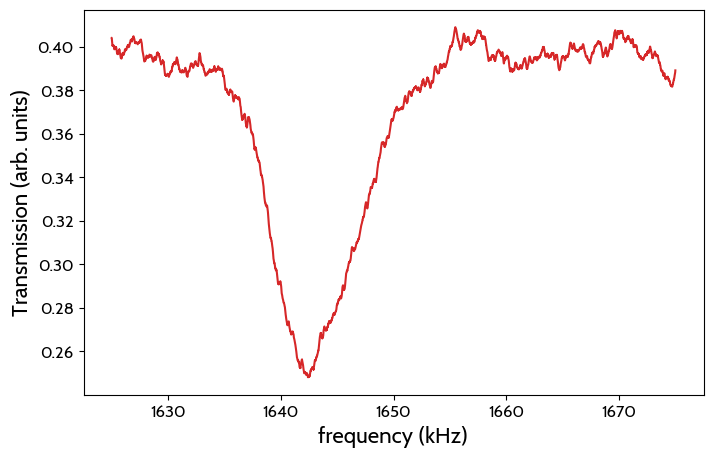

In [47]:
# 1.0 Vpp, 3.945 G, sweep 1625 to 1675 kHz
plot_average(range(693, 703), "high_freq_power_broadening/1.0Vpp_sweep", freq_low=1625, freq_high=1675)

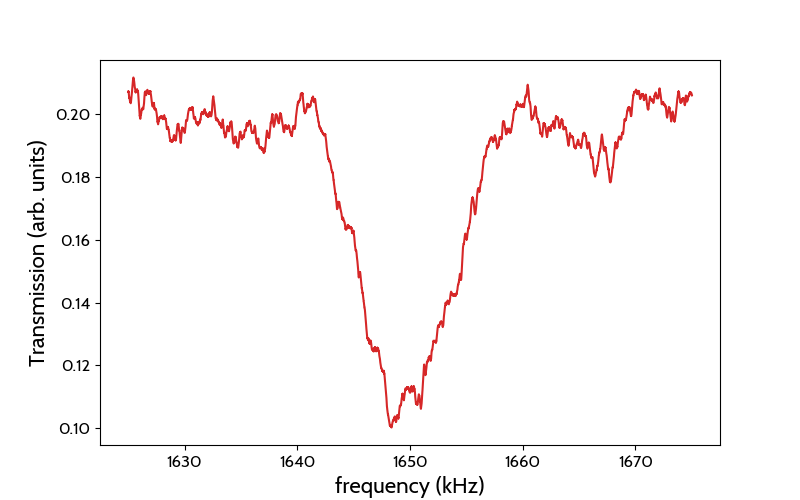

In [77]:
# 0.5 Vpp, 3.96 G, sweep 1625 to 1675 kHz
plot_average(range(703, 713), "high_freq_power_broadening/0.5Vpp_sweep", freq_low=1625, freq_high=1675)

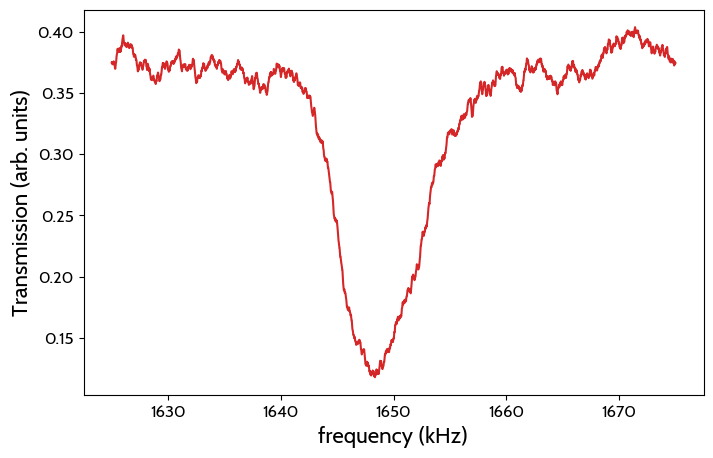

In [65]:
# fine 0.5 Vpp, 3.96 G, sweep 1625 to 1675 kHz
plot_average(range(713, 733), "high_freq_power_broadening/0.5Vpp_sweep", freq_low=1625, freq_high=1675)

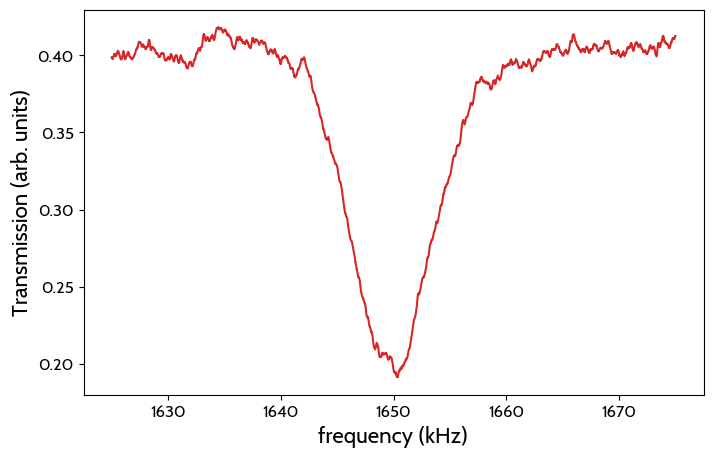

In [70]:
# 1.5 Vpp, 3.96 G, sweep 1625 to 1675 kHz
plot_average(range(733, 743), "high_freq_power_broadening/1.5Vpp_sweep", freq_low=1625, freq_high=1675)

In [76]:
%matplotlib ipympl

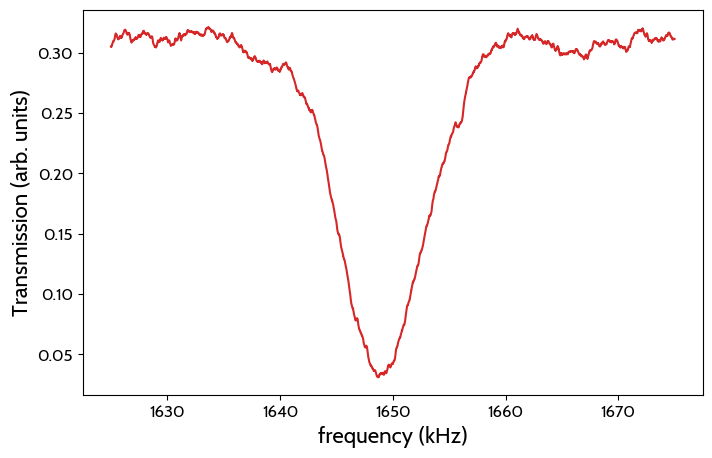

In [72]:
# 2.0 Vpp, 3.96 G, sweep 1625 to 1675 kHz
plot_average(range(743, 752), "high_freq_power_broadening/2.0Vpp_sweep", freq_low=1625, freq_high=1675)

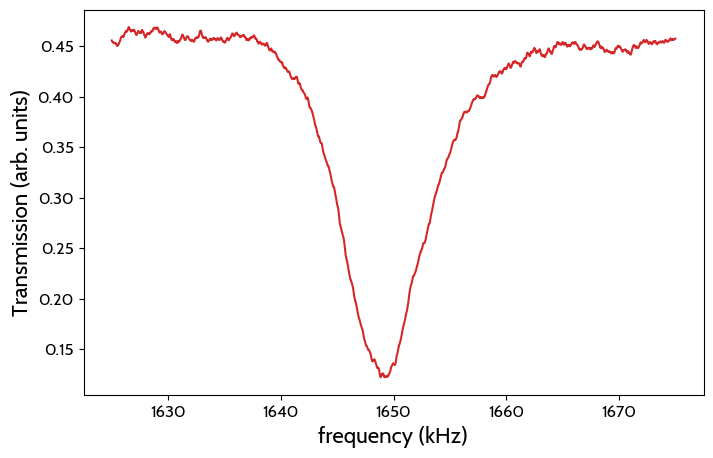

In [75]:
# 2.5 Vpp, 3.96 G, sweep 1625 to 1675 kHz
plot_average(range(753, 763), "high_freq_power_broadening/2.5Vpp_sweep", freq_low=1625, freq_high=1675)

In [ ]:
# rf coils - about 50 mG at 5 Vamp, and 0.12 amps; 70 mG at 6.5 Vamp and 0.16 amps

## Bulk Data Processing

### high freq

In [229]:
%matplotlib inline

In [170]:
import glob

high_freq_sweeps = glob.glob("data/31/high_freq_power_broadening/*.npz")
    
all_data_numbers_high = {} #dictionary of frequency: list of data numbers
for sweep in high_freq_sweeps:
    pow = float(sweep.split("broadening\\")[-1].split("Vpp_")[0])
    if pow not in all_data_numbers_high:
        all_data_numbers_high[pow] = []
    all_data_numbers_high[pow].append(sweep)

In [247]:
# fit to lorenzian
def lorentzian(f, f0, gamma, A, B):
    return A * (gamma**2 / ((f - f0)**2 + gamma**2)) + B

def fit_lorentzian_high(filename, plot = False):
    data = load_waveforms(filename)
    t, V2 = data[1][0], data[2][1]
    N = 100
    t = np.convolve(t, np.ones(N)/N, mode='valid')
    V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
    frequencies = np.linspace(1625, 1675, len(t))

    popt, pcov = curve_fit(lorentzian, frequencies, V2, p0=[1650, 3, -0.1, 0.4])
    if plot:
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.plot(frequencies, V2, label='Data', color='tab:green')
        ax.plot(frequencies, lorentzian(frequencies, *popt), label='Lorentzian Fit', color='k', linestyle='--', alpha=0.8)
        ax.set_xlabel('Frequency (kHz)')
        ax.set_ylabel('Transmission (arb. units)')
        ax.grid(True, linestyle='--', alpha=0.5)
        fwhm = popt[1] * 2
        ax.axvspan(popt[0] - fwhm/2, popt[0] + fwhm/2, alpha=0.2, color='red', linestyle='--', label='FWHM')

        ax.legend()
    return popt[1] * 2, np.sqrt(np.diag(pcov))[1] * 2


(7.172502662912344, 0.05650878200189753)

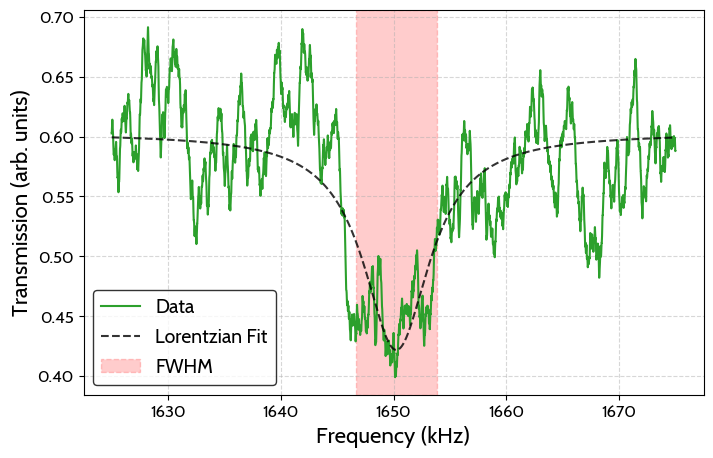

In [248]:
fit_lorentzian_high("data/31/high_freq_power_broadening/0.5Vpp_sweep_715.npz", plot=True)

In [200]:
fwhm_values_high = []
fwhm_uncertainties_high = []
powers = []
for power in all_data_numbers_high:
    powers.append(power)
    fwhms = []
    uncertainties = []
    for sweep in all_data_numbers_high[power]:
        fwhm, fwhm_uncertainty = np.abs(fit_lorentzian_high(sweep))
        fwhms.append(fwhm)
        uncertainties.append(fwhm_uncertainty)
    fwhm_values_high.append(np.average(fwhms, weights=1/np.array(uncertainties)**2))
    fwhm_uncertainties_high.append(np.std(fwhms)/np.sqrt(len(fwhms)))

powers_high = np.array(powers) ** 2
fwhm_values_high = np.array(fwhm_values_high)
fwhm_uncertainties_high = np.array(fwhm_uncertainties_high)

[0.06877694 7.68671675] [0.06732135 0.3329741 ]


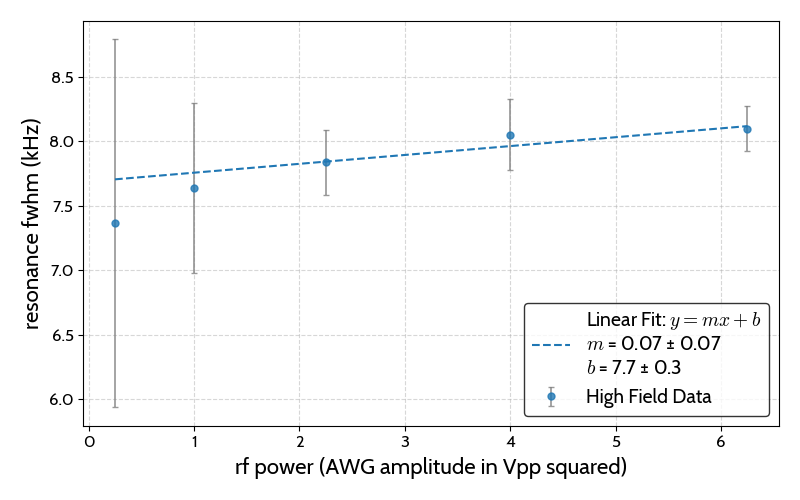

In [222]:
def f(x, a, b):
    return a * x + b

popt, pcov = curve_fit(f, powers_high, fwhm_values_high, sigma=fwhm_uncertainties_high, absolute_sigma=True)

fig, ax = plt.subplots(figsize=(8, 5), tight_layout=True)
ax.errorbar(powers_high, fwhm_values_high, yerr=fwhm_uncertainties_high, color = "tab:blue", fmt='o', ms=5, ecolor='gray', alpha=0.8, elinewidth=1.25, capsize=2, label='High Field Data')
ax.plot(powers_high, f(np.array(powers_high), *popt), color='tab:blue', label=f'Linear Fit: $y = m x + b$\n$m$ = {popt[0]:.2f} ± {np.sqrt(pcov[0, 0]):.2f}\n$b$ = {popt[1]:.1f} ± {np.sqrt(pcov[1, 1]):.1f}', linestyle='--')
ax.legend()
ax.set_xlabel('rf power (AWG amplitude in Vpp squared)')
ax.set_ylabel('resonance fwhm (kHz)')
ax.grid(True, linestyle='--', alpha=0.5)
print(popt, np.sqrt(np.diag(pcov)))

fig.savefig("figures/power_broadening_high_freq.svg", format='svg')

### low freq

In [164]:
low_freq_sweeps = glob.glob("data/31/low_freq_power_broadening/*.npz")
    
all_data_numbers_low = {} #dictionary of frequency: list of data numbers
for sweep in low_freq_sweeps:
    pow = float(sweep.split("broadening\\")[-1].split("Vpp_")[0])
    if pow not in all_data_numbers_low:
        all_data_numbers_low[pow] = []
    all_data_numbers_low[pow].append(sweep)

In [249]:
# fit to lorenzian
def lorentzian(f, f0, gamma, A, B):
    return A * (gamma**2 / ((f - f0)**2 + gamma**2)) + B

def fit_lorentzian_low(filename, plot = False):
    data = load_waveforms(filename)
    t, V2 = data[1][0], data[2][1]
    N = 100
    t = np.convolve(t, np.ones(N)/N, mode='valid')
    V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
    frequencies = np.linspace(743, 752, len(t))

    popt, pcov = curve_fit(lorentzian, frequencies, V2, p0=[747.5, 3, -0.1, 0.4])
    if plot:
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.plot(frequencies, V2, label='Data', color='tab:green')
        ax.plot(frequencies, lorentzian(frequencies, *popt), label='Lorentzian Fit', color='k', linestyle='--', alpha=0.8)
        ax.set_xlabel('Frequency (kHz)')
        ax.set_ylabel('Transmission (arb. units)')
        ax.grid(True, linestyle='--', alpha=0.5)
        fwhm = popt[1] * 2
        ax.axvspan(popt[0] - fwhm/2, popt[0] + fwhm/2, alpha=0.2, color='red', linestyle='--', label='FWHM')
        ax.legend()
    return popt[1] * 2, np.sqrt(np.diag(pcov))[1] * 2


(-1.7502222976415303, 0.001920137577910048)

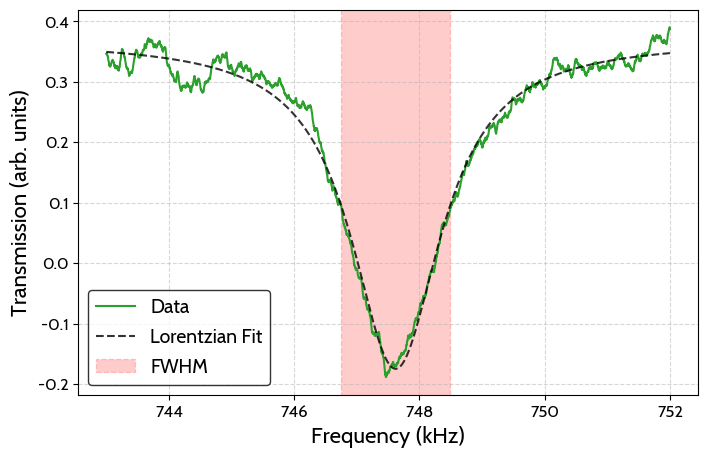

In [250]:
fit_lorentzian_low("data/31/low_freq_power_broadening/1.3Vpp_sweep_645.npz", plot=True)

In [205]:
fwhm_values_low = []
fwhm_uncertainties_low = []
powers = []
for power in all_data_numbers_low:
    powers.append(power)
    fwhms = []
    fwhm_uncs = []
    for sweep in all_data_numbers_low[power]:
        fwhm, fwhm_uncertainty = np.abs(fit_lorentzian_low(sweep))
        fwhms.append(fwhm)
        fwhm_uncs.append(fwhm_uncertainty)
    
    fwhm_values_low.append(np.average(fwhms, weights=1/np.array(fwhm_uncs)**2))
    fwhm_uncertainties_low.append(np.std(fwhms)/np.sqrt(len(fwhms)))

powers_low = np.array(powers) ** 2
fwhm_values_low = np.array(fwhm_values_low)
fwhm_uncertainties_low = np.array(fwhm_uncertainties_low)

[0.23020312 1.27320746] [0.01836225 0.0348036 ]


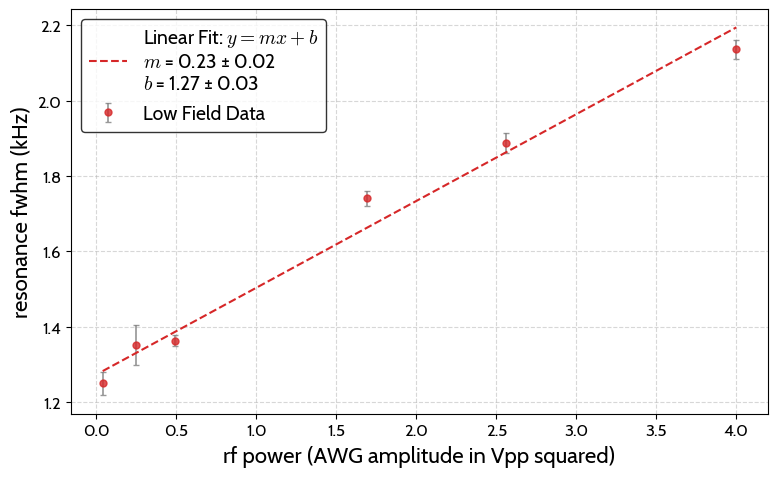

In [235]:
def f(x, a, b):
    return a * x + b
popt, pcov = curve_fit(f, powers_low, fwhm_values_low, sigma=fwhm_uncertainties_low)

fig, ax = plt.subplots(figsize=(8, 5), tight_layout=True)
ax.errorbar(powers_low, fwhm_values_low, yerr=fwhm_uncertainties_low, color = "tab:red", fmt='o', ms=5, ecolor='gray', alpha=0.8, elinewidth=1.25, capsize=2, label  = "Low Field Data")
ax.plot(powers_low, f(np.array(powers_low), *popt), color='tab:red', label=f'Linear Fit: $y = m x + b$\n$m$ = {popt[0]:.2f} ± {np.sqrt(pcov[0, 0]):.2f}\n$b$ = {popt[1]:.2f} ± {np.sqrt(pcov[1, 1]):.2f}', linestyle='--')
ax.legend()
ax.set_xlabel('rf power (AWG amplitude in Vpp squared)')
ax.set_ylabel('resonance fwhm (kHz)')
ax.grid(True, linestyle='--', alpha=0.5)
print(popt, np.sqrt(np.diag(pcov)))
fig.savefig("figures/power_broadening_low_freq.svg", format='svg')

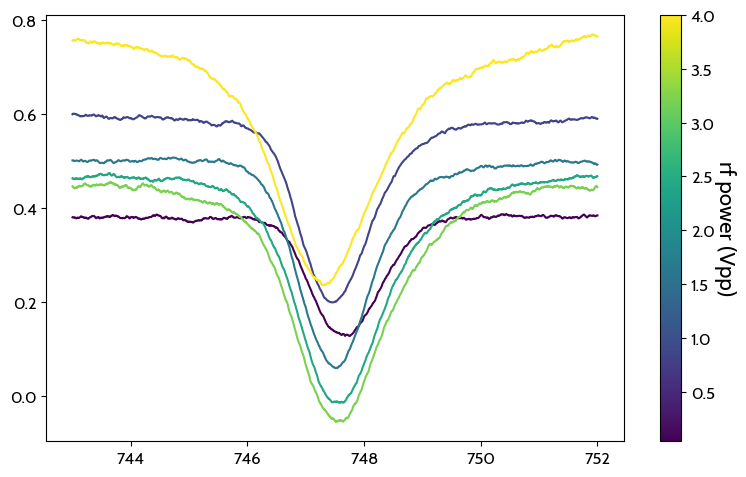

In [244]:
# average and plot together:
from matplotlib import cm
fig, ax = plt.subplots(figsize=(8, 5), tight_layout=True)
powers = powers_low
colors = cm.viridis(np.linspace(0, 1, len(powers)))

for power in all_data_numbers_low:
    transmissions = []
    for sweep in all_data_numbers_low[power]:
        data = load_waveforms(sweep)
        t, V2 = data[1][0], data[2][1]
        N = 100
        t = np.convolve(t, np.ones(N)/N, mode='valid')
        V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
        frequencies = np.linspace(743, 752, len(t))
        transmissions.append(V2)
    avg_transmission = np.mean(transmissions, axis=0)
    ax.plot(frequencies, avg_transmission, label=f'{power} Vpp', color=colors[list(all_data_numbers_low.keys()).index(power)])

# colorbar
sm = cm.ScalarMappable(cmap=cm.viridis, norm=plt.Normalize(vmin=min(powers), vmax=max(powers)))
# add to plot
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label('rf power (Vpp)', rotation=270, labelpad=15)